### 01 — EndoVis Dataset 1 preprocessing (YOLO Pose)

**Stage 1, preliminary experiment.** Uses only `train1_labels.json`, the extracted Dataset 1 PNG frames and `timestamps.csv`. The left/right robotic pose TXT files are inspected **but not used as jaw-tip ground truth**. Outputs two keypoints (`LeftClasperPoint`, `RightClasperPoint`) per instrument. A chronological 80/20 split is used for a preliminary validation; it does **not** measure cross-sequence generalization.

Run from the repository root (where this notebook and `EndoVisPoseAnnotation/` are siblings). No automatic search for other datasets.

In [2]:
from pathlib import Path
import json, shutil, re
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

ROOT = Path.cwd()
SOURCE = ROOT / "EndoVisPoseAnnotation"

# Corrected Dataset 1 path
POSE_DIR = (
    SOURCE
    / "Tracking_Robotic_Training"
    / "Training"
    / "Dataset1"
)

FRAMES = POSE_DIR / "EndoVis_Frames_set1" / "Dataset1"

ANNOTATIONS = SOURCE / "train_labels" / "train1_labels.json"
OUT = ROOT / "EndoVis_YOLO_Pose_Dataset1"

KEYPOINTS = ["LeftClasperPoint", "RightClasperPoint"]
FPS = 25.0
PADDING = 20

# Verify paths
print("Repository:", ROOT)

for p in (FRAMES, ANNOTATIONS, FRAMES / "timestamps.csv"):
    print(p, "exists:", p.exists())
    if not p.exists():
        raise FileNotFoundError(p)

Repository: c:\Users\default.LAPTOP-914PEJ5D\Documents\CV\Computer-Vison-Course-project
c:\Users\default.LAPTOP-914PEJ5D\Documents\CV\Computer-Vison-Course-project\EndoVisPoseAnnotation\Tracking_Robotic_Training\Training\Dataset1\EndoVis_Frames_set1\Dataset1 exists: True
c:\Users\default.LAPTOP-914PEJ5D\Documents\CV\Computer-Vison-Course-project\EndoVisPoseAnnotation\train_labels\train1_labels.json exists: True
c:\Users\default.LAPTOP-914PEJ5D\Documents\CV\Computer-Vison-Course-project\EndoVisPoseAnnotation\Tracking_Robotic_Training\Training\Dataset1\EndoVis_Frames_set1\Dataset1\timestamps.csv exists: True


### 1. Inspect frames, timestamps, and pose files

The pose files are robot-derived instrument position/orientation parameters, not annotated 2D jaw-tip positions. We preserve them as separate inputs for later study. Their row-to-frame alignment and units must be checked before using them for kinematics.

In [3]:
frame_paths = sorted(FRAMES.glob("*.png"))
times = pd.read_csv(FRAMES / "timestamps.csv")
print("PNG frames:", len(frame_paths))
print("Timestamp rows:", len(times), "columns:", list(times.columns))
print(times.head(3).to_string(index=False))
print("Pose TXT files:")
for p in sorted(POSE_DIR.glob("*.txt")):
    print(" ", p.name, "size:", p.stat().st_size, "bytes")
    with p.open(encoding="utf-8", errors="replace") as f:
        for _ in range(2):
            line = f.readline().strip()
            if line: print("    ", line[:160])
if not {'filename','timestamp_seconds'}.issubset(times.columns):
    raise ValueError("timestamps.csv must contain filename and timestamp_seconds columns")
if times['filename'].duplicated().any():
    raise ValueError("Duplicate filenames in timestamps.csv")


PNG frames: 1107
Timestamp rows: 1107 columns: ['frame_id', 'filename', 'timestamp_seconds']
 frame_id           filename  timestamp_seconds
        1 img_000001_raw.png               0.00
        2 img_000002_raw.png               0.04
        3 img_000003_raw.png               0.08
Pose TXT files:
  Left_Instrument_Pose.txt size: 59497 bytes
     115 335 0.905175 -0.425039 0.9534 -0.301709 4.82992
     115 335 0.905175 -0.425039 0.9534 -0.301709 4.82992
  Right_Instrument_Pose.txt size: 62285 bytes
     573 346 -0.999906 -0.0136973 -0.998783 -0.0493226 0.886398
     573 346 -0.999906 -0.0136973 -0.998783 -0.0493226 0.886398


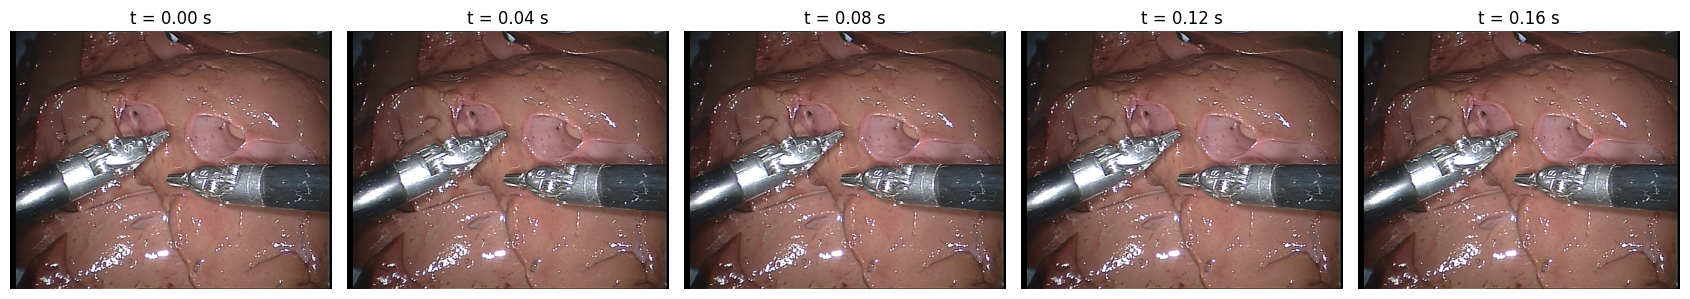

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(17, 4))
for ax, (_, row) in zip(axes, times.head(5).iterrows()):
    p = FRAMES / Path(str(row['filename'])).name
    im = cv2.imread(str(p))
    if im is None: raise FileNotFoundError(p)
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    ax.set_title(f"t = {float(row['timestamp_seconds']):.2f} s")
    ax.axis('off')
plt.tight_layout(); plt.show()


## 2. Inspect ground-truth annotations

The original JSON contains source-machine absolute paths; we use only each filename's basename to find the local image.

In [5]:
with ANNOTATIONS.open(encoding="utf-8") as f:
    records = json.load(f)
assert isinstance(records, list)
annotated = [r for r in records if r.get('annotations')]
print("Total JSON records:", len(records))
print("Annotated records:", len(annotated))
print("Classes:", sorted({a.get('class') for r in annotated for a in r['annotations']}))
print("Instrument IDs:", sorted({str(a.get('id')) for r in annotated for a in r['annotations']}))
print("First annotated filename:", Path(annotated[0]['filename']).name if annotated else 'None')


Total JSON records: 1107
Annotated records: 210
Classes: ['EndPoint', 'HeadPoint', 'LeftClasperPoint', 'RightClasperPoint', 'ShaftPoint', 'TrackedPoint']
Instrument IDs: ['tool1', 'tool2']
First annotated filename: img_000060_raw.png


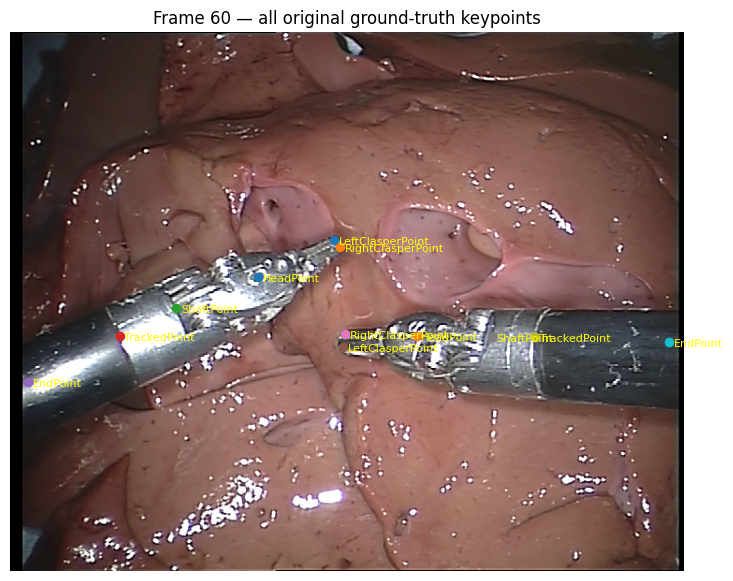

In [6]:
frame_number = 60
p = FRAMES / f"img_{frame_number:06d}_raw.png"
matching = [r for r in records if Path(r.get('filename','')).name == p.name]
if not matching: raise ValueError(f"No JSON record for {p.name}")
im = cv2.imread(str(p))
if im is None: raise FileNotFoundError(p)
plt.figure(figsize=(11, 7)); plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
for a in matching[0].get('annotations', []):
    plt.scatter(a['x'], a['y'], s=35)
    plt.text(a['x'] + 5, a['y'] + 5, str(a['class']), fontsize=8, color='yellow')
plt.title('Frame 60 — all original ground-truth keypoints'); plt.axis('off'); plt.show()


### 3. Check annotations and choose chronological split

The current converter requires both jaw tips for every instrument represented by a target landmark. Conflicting duplicates or missing jaw tips cause the **whole frame** to be excluded, consistent with the original notebook. We log the reasons instead of silently dropping frames. For now the approximate box covers the two jaw tips plus 20 pixels of padding, **not the whole instrument**.

In [7]:
def frame_index(name):
    match = re.search(r'img_(\d+)_raw', name)
    if not match: raise ValueError(f"Cannot parse frame index from {name}")
    return int(match.group(1))

annotated = sorted(annotated, key=lambda r: frame_index(Path(r['filename']).name))
split_idx = int(0.8 * len(annotated))
train_records, val_records = annotated[:split_idx], annotated[split_idx:]
print(f"Annotated: {len(annotated)} | train: {len(train_records)} | val: {len(val_records)}")
print('Train frame range:', frame_index(Path(train_records[0]['filename']).name), '-', frame_index(Path(train_records[-1]['filename']).name))
print('Val frame range:', frame_index(Path(val_records[0]['filename']).name), '-', frame_index(Path(val_records[-1]['filename']).name))


Annotated: 210 | train: 168 | val: 42
Train frame range: 60 - 895
Val frame range: 900 - 1105


In [8]:
def build_label(record):
    filename = Path(record['filename']).name
    image_path = FRAMES / filename
    image = cv2.imread(str(image_path))
    if image is None: return None, f"missing image: {filename}"
    height, width = image.shape[:2]
    tools = {}
    for a in record.get('annotations', []):
        name = a.get('class')
        if name not in KEYPOINTS: continue
        tool_id = str(a.get('id'))
        if name in tools.setdefault(tool_id, {}):
            return None, f"duplicate {name}: {filename}, {tool_id}"
        try: x, y = float(a['x']), float(a['y'])
        except (ValueError, TypeError, KeyError):
            return None, f"invalid coordinate: {filename}, {tool_id}"
        if not (np.isfinite(x) and np.isfinite(y) and 0 <= x < width and 0 <= y < height):
            return None, f"out-of-bounds coordinate: {filename}, {tool_id}"
        tools[tool_id][name] = (x, y)
    lines = []
    for tool_id, points in tools.items():
        if not all(k in points for k in KEYPOINTS):
            return None, f"missing jaw tip: {filename}, {tool_id}"
        coords = np.array([points[k] for k in KEYPOINTS])
        xmin, xmax = max(0, coords[:,0].min()-PADDING), min(width, coords[:,0].max()+PADDING)
        ymin, ymax = max(0, coords[:,1].min()-PADDING), min(height, coords[:,1].max()+PADDING)
        if xmax <= xmin or ymax <= ymin: return None, f"invalid box: {filename}, {tool_id}"
        values = [0, (xmin+xmax)/(2*width), (ymin+ymax)/(2*height), (xmax-xmin)/width, (ymax-ymin)/height]
        for x,y in coords: values.extend([x/width, y/height, 2])
        lines.append(' '.join(f'{v:.8f}' if isinstance(v, (float, np.floating)) else str(v) for v in values))
    if not lines: return None, f"no target keypoints: {filename}"
    return lines, None

summary = []
for split, subset in [('train', train_records), ('val', val_records)]:
    for r in subset:
        lines, err = build_label(r)
        summary.append({'split':split, 'filename':Path(r['filename']).name, 'valid':err is None, 'reason':err or ''})
report = pd.DataFrame(summary)
print(report.groupby(['split','valid']).size().to_string())
print('Rejected records:')
print(report[~report.valid].to_string(index=False))


split  valid
train  False      1
       True     167
val    True      42
Rejected records:
split           filename  valid                                                 reason
train img_000130_raw.png  False duplicate RightClasperPoint: img_000130_raw.png, tool1


### 4. Write dataset and configuration

For safety, this cell **refuses to overwrite an existing output directory**. To regenerate, rename or delete `EndoVis_YOLO_Pose_Dataset1` first. It does not modify your original `EndoVis_YOLO_Pose/`.

In [9]:
if OUT.exists():
    raise FileExistsError(f"Output already exists: {OUT}. Rename or delete it before regenerating.")
for split in ('train','val'):
    (OUT/'images'/split).mkdir(parents=True)
    (OUT/'labels'/split).mkdir(parents=True)

for split, subset in [('train',train_records), ('val',val_records)]:
    for r in subset:
        filename = Path(r['filename']).name
        lines, err = build_label(r)
        if err: continue
        shutil.copy2(FRAMES/filename, OUT/'images'/split/filename)
        (OUT/'labels'/split/(Path(filename).stem+'.txt')).write_text('\n'.join(lines)+'\n', encoding='utf-8')
report.to_csv(OUT/'conversion_report.csv', index=False)
# YAML generated without an extra PyYAML dependency
config = (f'path: "{OUT.as_posix()}"\n'
          'train: images/train\nval: images/val\n'
          'names:\n  0: jaw_tip_region\n'
          'kpt_shape: [2, 3]\nflip_idx: [1, 0]\n')
(OUT/'data.yaml').write_text(config, encoding='utf-8')
print('Saved dataset to:', OUT)
print(config)


Saved dataset to: c:\Users\default.LAPTOP-914PEJ5D\Documents\CV\Computer-Vison-Course-project\EndoVis_YOLO_Pose_Dataset1
path: "c:/Users/default.LAPTOP-914PEJ5D/Documents/CV/Computer-Vison-Course-project/EndoVis_YOLO_Pose_Dataset1"
train: images/train
val: images/val
names:
  0: jaw_tip_region
kpt_shape: [2, 3]
flip_idx: [1, 0]



### 5. Visualize converted YOLO Pose labels

Draw the approximate bounding box and two jaw-tip landmarks from the **exported** text files, to verify coordinate normalization and ordering.

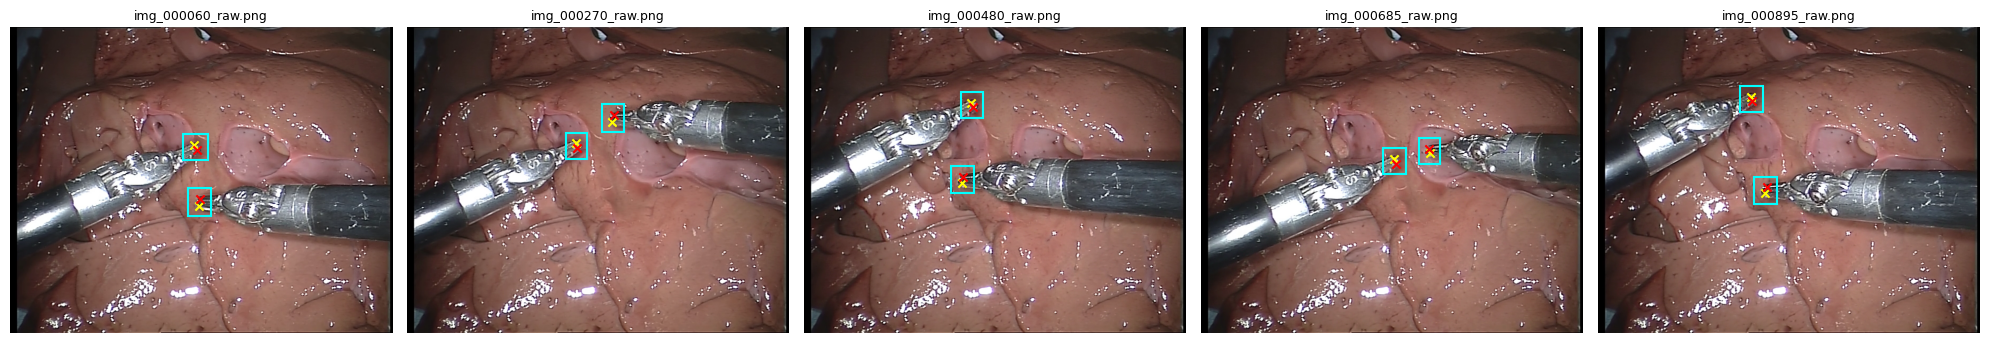

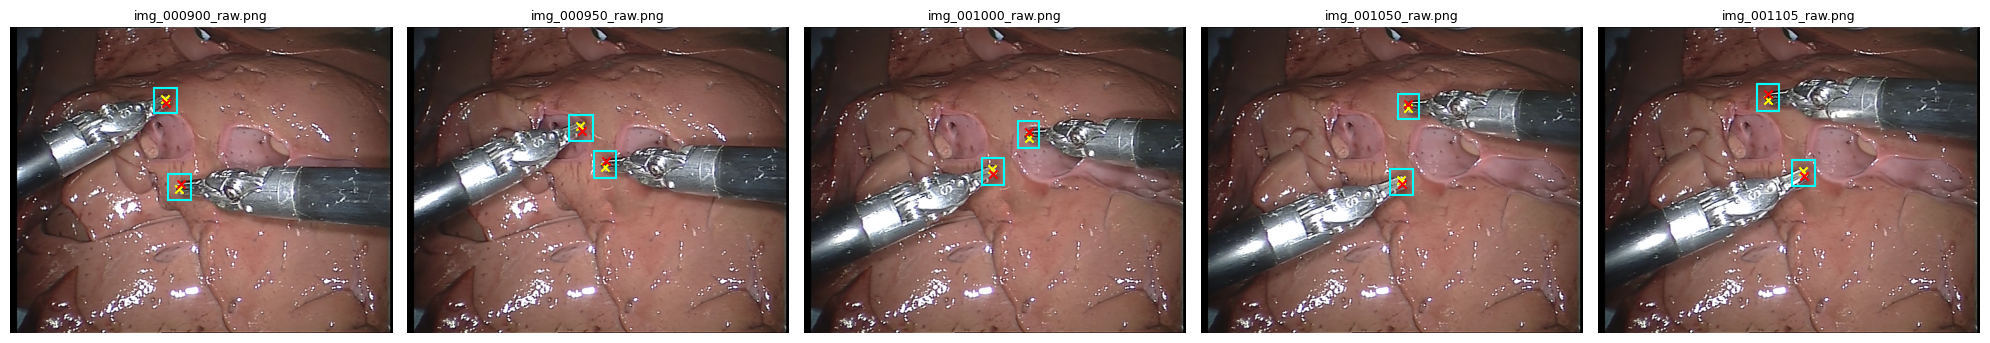

In [10]:
def show_converted(split='train', n=5):
    paths = sorted((OUT/'images'/split).glob('*.png'))
    if not paths: raise ValueError(f'No images in {split}')
    chosen = [paths[i] for i in np.linspace(0, len(paths)-1, min(n,len(paths)), dtype=int)]
    fig, axes = plt.subplots(1, len(chosen), figsize=(4*len(chosen), 4), squeeze=False)
    for ax,p in zip(axes[0], chosen):
        im = cv2.imread(str(p)); h,w = im.shape[:2]
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        label = (OUT/'labels'/split/(p.stem+'.txt')).read_text().strip()
        for line in label.splitlines():
            vals = list(map(float, line.split()))
            _,xc,yc,bw,bh,*kps = vals
            x0,y0 = (xc-bw/2)*w, (yc-bh/2)*h
            ax.add_patch(plt.Rectangle((x0,y0),bw*w,bh*h,fill=False,edgecolor='cyan',linewidth=1.5))
            for j in range(2):
                x,y,v = kps[3*j:3*j+3]
                if v > 0:
                    ax.scatter(x*w,y*h,s=35,marker='x',color=['yellow','red'][j])
        ax.set_title(p.name, fontsize=9); ax.axis('off')
    plt.tight_layout(); plt.show()
show_converted('train')
show_converted('val')


### 6. Final integrity checks and next steps

This notebook prepares the data only; it **does not train YOLO Pose**. The pose TXT files and timestamps remain in the original Dataset 1 folder. Next: train a small pretrained YOLO Pose model and evaluate RMSE/PCK on the held-out annotated frames. Because all frames are from one video, interpret validation as a preliminary within-sequence test.

In [11]:
for split in ('train','val'):
    ims = {p.stem for p in (OUT/'images'/split).glob('*.png')}
    labs = {p.stem for p in (OUT/'labels'/split).glob('*.txt')}
    assert ims == labs, (split, 'image-label mismatch', ims^labs)
    for p in (OUT/'labels'/split).glob('*.txt'):
        for line in p.read_text().splitlines():
            fields = list(map(float, line.split()))
            assert len(fields) == 11, (p, len(fields))  # class + box(4) + 2*(x,y,v)
            assert all(0 <= v <= 1 for v in fields[1:5])
            assert all(0 <= fields[i] <= 1 for i in (5,6,8,9))
            assert fields[7] == 2 and fields[10] == 2
    print(f'{split}: {len(ims)} image-label pairs verified')
print('Ready for Stage 1 training. Dataset YAML:', OUT/'data.yaml')


train: 167 image-label pairs verified
val: 42 image-label pairs verified
Ready for Stage 1 training. Dataset YAML: c:\Users\default.LAPTOP-914PEJ5D\Documents\CV\Computer-Vison-Course-project\EndoVis_YOLO_Pose_Dataset1\data.yaml
